## Basic perceptron

output = activation_function(sum(weights * inputs) + bias)

activation fun: step function

AND gate inputs and expected outputs
training_data = [
    (np.array([0, 0]), 0),
    (np.array([0, 1]), 0),
    (np.array([1, 0]), 0),
    (np.array([1, 1]), 1)
]

new_weights = weights + learning_rate * (error * inputs)

DEBUG: Initial: Weights = [ 0.72072068 -0.24491419], Bias = -0.6123137163758992

DEBUG: Iteration: 0 ===========================================================================================================

DEBUG: Prediction 
predicted = ∑(inputs * weights) + bias
0 = ∑([0 0] * [ 0.72072068 -0.24491419]) + -0.6123137163758992

DEBUG: Error 
error = expected - predicted
0 = 0 - 0

DEBUG: New weights 
new_weights = weights + learning_rate * (error * inputs)
[ 0.72072068 -0.24491419] = [ 0.72072068 -0.24491419] + 0.1 * (0 * [0 0])

DEBUG: New bias 
new_bias = bias + learning_rate * error
-0.6123137163758992 = -0.6123137163758992 + 0.1 * 0

DEBUG: Prediction 
predicted = ∑(inputs * weights) + bias
0 = ∑([0 1] * [ 0.72072068 -0.24491419]) + -0.6123137163758992

DEBUG: Error 
error = expected - predicted
0 = 0 - 0

DEBUG: New weights 
new_weights = weights + learning_rate * (error * inputs)
[ 0.72072068 -0.24491419] = [ 0.72072068 -0.24491419] + 0.1 * (0 * [0 1])

DEBUG: New bias 
new_bia

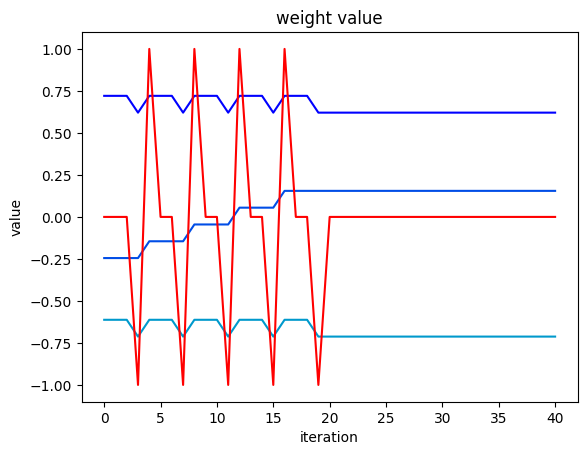

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# output = activation_function(sum(weights * inputs) + bias)
debug_mode = True

def debug_print(msg):
    if debug_mode:
        print(f"DEBUG: {msg}\n")

def perceptron(inputs, weights, bias):
    activation = np.sum(inputs * weights) + bias
    return 1 if activation > 0 else 0

def error_function(expected, predicted):
    return expected - predicted

def train(inputs, expected, weights, bias, learning_rate):

    predicted = perceptron(inputs, weights, bias)
    debug_print(f"Prediction \npredicted = ∑(inputs * weights) + bias\n{predicted} = ∑({inputs} * {weights}) + {bias}")

    error = error_function(expected, predicted)
    debug_print(f"Error \nerror = expected - predicted\n{error} = {expected} - {predicted}")

    new_weights = weights + learning_rate * (error * inputs)
    debug_print(f"New weights \nnew_weights = weights + learning_rate * (error * inputs)\n{new_weights} = {weights} + {learning_rate} * ({error} * {inputs})")

    weights = new_weights
    new_bias = bias + learning_rate * error
    debug_print(f"New bias \nnew_bias = bias + learning_rate * error\n{new_bias} = {bias} + {learning_rate} * {error}")

    bias = new_bias
    return weights, bias, error

# np.random.seed(42)
weights = np.random.rand(2) * 2 - 1
bias = np.random.rand() * 2 - 1
learning_rate = 0.1

training_data = [
    (np.array([0, 0]), 0),
    (np.array([0, 1]), 0),
    (np.array([1, 0]), 0),
    (np.array([1, 1]), 1)
]

w0_history = [weights[0]]
w1_history = [weights[1]]
b_history = [bias]
e_history = [0]
debug_print(f"Initial: Weights = {weights}, Bias = {bias}")

for i in range(10):
    debug_print(f"Iteration: {i} ===========================================================================================================")
    for inputs, expected in training_data:
        weights, bias, error = train(inputs, expected, weights, bias, learning_rate)
        # print(f"Error = {error}")
        w0_history.append(weights[0])
        w1_history.append(weights[1])
        b_history.append(bias)
        e_history.append(error)
    # print(f"Iteration {i}: Weights = {weights}, Bias = {bias}")

for inputs, expected in training_data:
    print(f"Output for ({inputs}) = {perceptron(np.array(inputs), weights, bias)}")

plt.plot(range(len(w0_history)), w0_history, color=(0.0, 0.0, 1.0))
plt.plot(range(len(w1_history)), w1_history, color=(0.0, 0.3, 0.9))
plt.plot(range(len(b_history)), b_history, color=(0.0, 0.6, 0.8))
plt.plot(range(len(e_history)), e_history, color=(1.0, 0.0, 0.0))
plt.title('weight value')
plt.xlabel('iteration')
plt.ylabel('value')
plt.show()

In [2]:
# AND perceptron test
input=np.array([1, 1])
print(weights)
print(bias)
print(perceptron(np.array(input), weights, bias))

[0.62072068 0.15508581]
-0.7123137163758991
1


## Linear perceptron
mnist images 28x28, number classification
0 or 1

### Explore dataset

In [3]:
from datasets import load_dataset
import numpy as np

dataset = load_dataset("ylecun/mnist")
print(dataset)

example = dataset["train"][0]

print(f"Keys: {example.keys()}")   # dict_keys(['image', 'label'])
# print(example["label"]) # e.g. 5

image = example["image"]
image_array = np.array(image)

# print(image_array.shape)  # (28, 28)
# print(image_array)

# Normalize
image_array = image_array / 255.0

# Binarize
image_binary = (image_array > 0.5).astype(int)

# Flatten to 784 vector
image_flat = image_binary.flatten()

print(f"Image flat shape: {image_flat.shape}")  # (784,)
#print(image_flat)

C:\Users\Dave\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})
Keys: dict_keys(['image', 'label'])
Image flat shape: (784,)


#### preprocess()
original images are b&w 256 level brightness matrix
->
transform to binary b&w tresholded at 0.5, flattened vector

#### filter()
only train to detect 0 or 1 for now

In [4]:
debug_mode = False

def preprocess(example):
    img = np.array(example["image"]) / 255.0
    img = (img > 0.5).astype(int)
    example["input"] = img.flatten()
    return example

def filter_01(example):
    return example["label"] in [0, 1]

dataset = load_dataset("ylecun/mnist")
dataset = dataset.map(preprocess)

small_train_data = dataset["train"].filter(filter_01)
small_test_data = dataset["test"].filter(filter_01)

as much input neurons as input pixels, 
one output neuron

In [5]:
debug_mode = False

weights = np.random.rand(28*28)
bias = np.random.rand()
learning_rate = 0.1


w0_history = [weights[0]]
w1_history = [weights[1]]
b_history = [bias]
e_history = [0]
# debug_print(f"Initial: Weights = {weights}, Bias = {bias}")

i = 0
l = len(small_train_data)
for data in small_train_data:
    print(f"{i}/{l}")
    i+=1
    inputs = np.array(data['input'])
    expected = data['label']
    weights, bias, error = train(inputs, expected, weights, bias, learning_rate)
    # print(f"Error = {error}")
    w0_history.append(weights[0])
    w1_history.append(weights[1])
    b_history.append(bias)
    e_history.append(error)
    # print(f"Iteration {i}: Weights = {weights}, Bias = {bias}")

accurate_predictions = 0
for data in small_test_data:
    inputs = data['input']
    expected = data['label']
    prediction = perceptron(inputs, weights, bias)
    accurate_predictions += 1 if prediction == expected else 0
accuracy = accurate_predictions / len(small_test_data)
print(f"Accuracy: {accuracy}")

plt.plot(range(len(w0_history)), w0_history, color=(0.0, 0.0, 1.0))
plt.plot(range(len(w1_history)), w1_history, color=(0.0, 0.6, 0.8))
plt.plot(range(len(b_history)), b_history, color=(0.0, 0.9, 0.2))
plt.plot(range(len(e_history)), e_history, color=(1.0, 0.0, 0.0))
plt.title('weight value')
plt.xlabel('iteration')
plt.ylabel('value')
plt.show()

0/12665
1/12665
2/12665
3/12665
4/12665
5/12665
6/12665
7/12665
8/12665
9/12665
10/12665
11/12665
12/12665
13/12665
14/12665
15/12665
16/12665
17/12665
18/12665
19/12665
20/12665
21/12665
22/12665
23/12665
24/12665
25/12665
26/12665
27/12665
28/12665
29/12665
30/12665
31/12665
32/12665
33/12665
34/12665
35/12665
36/12665
37/12665
38/12665
39/12665
40/12665
41/12665
42/12665
43/12665
44/12665
45/12665
46/12665
47/12665
48/12665
49/12665
50/12665
51/12665
52/12665
53/12665
54/12665
55/12665
56/12665
57/12665
58/12665
59/12665
60/12665
61/12665
62/12665
63/12665
64/12665
65/12665
66/12665
67/12665
68/12665
69/12665
70/12665
71/12665
72/12665
73/12665
74/12665
75/12665
76/12665
77/12665
78/12665
79/12665
80/12665
81/12665
82/12665
83/12665
84/12665
85/12665
86/12665
87/12665
88/12665
89/12665
90/12665
91/12665
92/12665
93/12665
94/12665
95/12665
96/12665
97/12665
98/12665
99/12665
100/12665
101/12665
102/12665
103/12665
104/12665
105/12665
106/12665
107/12665
108/12665
109/12665
110/12665


KeyboardInterrupt: 

In [ ]:
print(accuracy)

0.9995271867612293


## Full classifier setup
- 28*28 input
- 10 output
- 28*28*10 weights
- 10 biases



In [8]:
full_train_data = dataset["train"]
full_test_data = dataset["test"]

weights = []
biases = []
for i in range(10):
    weights.append(np.random.rand(28*28) * 2 - 1)
    biases.append(np.random.rand() * 2 - 1)
learning_rate = 0.1


train

In [10]:

length = len(full_train_data)

for i in range(10):
    iteration = 0
    for data in full_train_data:
        print(f"Label: {i}, Iteration: {iteration}/{length}")
        iteration+=1
        inputs = np.array(data['input'])
        expected = 1 if data['label'] == i else 0
        weights[i], biases[i], error = train(inputs, expected, weights[i], biases[i], learning_rate)

Label: 0, Iteration: 0/60000
Label: 0, Iteration: 1/60000
Label: 0, Iteration: 2/60000
Label: 0, Iteration: 3/60000
Label: 0, Iteration: 4/60000
Label: 0, Iteration: 5/60000
Label: 0, Iteration: 6/60000
Label: 0, Iteration: 7/60000
Label: 0, Iteration: 8/60000
Label: 0, Iteration: 9/60000
Label: 0, Iteration: 10/60000
Label: 0, Iteration: 11/60000
Label: 0, Iteration: 12/60000
Label: 0, Iteration: 13/60000
Label: 0, Iteration: 14/60000
Label: 0, Iteration: 15/60000
Label: 0, Iteration: 16/60000
Label: 0, Iteration: 17/60000
Label: 0, Iteration: 18/60000
Label: 0, Iteration: 19/60000
Label: 0, Iteration: 20/60000
Label: 0, Iteration: 21/60000
Label: 0, Iteration: 22/60000
Label: 0, Iteration: 23/60000
Label: 0, Iteration: 24/60000
Label: 0, Iteration: 25/60000
Label: 0, Iteration: 26/60000
Label: 0, Iteration: 27/60000
Label: 0, Iteration: 28/60000
Label: 0, Iteration: 29/60000
Label: 0, Iteration: 30/60000
Label: 0, Iteration: 31/60000
Label: 0, Iteration: 32/60000
Label: 0, Iteration:

test

In [11]:
accurate_predictions = 0
for data in full_test_data:
    inputs = data['input']
    expected = data['label']

    prediction = 0
    for i in range(10):
        output = perceptron(inputs, weights[i], biases[i])
        if output == 1:
            prediction = i

    accurate_predictions += 1 if prediction == expected else 0
accuracy = accurate_predictions / len(full_test_data)
print(f"Accuracy: {accuracy}")

Accuracy: 0.7002


avoid local minimum -> random init
gradiant descent -> first calc all gradients, then update
stohastic grad desc -> 

### Results
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
|no.1|177 min|0.7002||
|no.2|9 min 24 sec|0.8294|predict argmax + sigmoid activation|


In [ ]:
def predict(input_data):
        prediction = 0
        for i in range(10):
            output = perceptron(input_data, weights[i], biases[i])
            if output == 1:
                prediction = i
        return prediction

handmade_input3 = [
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
]
print(predict(handmade_input3))



3


In [26]:
handmade_input8 = [
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
]
print(predict(handmade_input8))

3


In [25]:
handmade_input0 = [
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,
     0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
     0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
]
print(predict(handmade_input0))

0
